In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/tienen/handwritten-signature-verification/assignments_07-02-2022.tsv
/kaggle/input/datasets/tienen/handwritten-signature-verification/data/data/forged/ru.0950de17-485c-452f-855d-9005cb65d9fc__0001e12109--61fe61a32db8902a70a19018__lid_1644061177668_1_JPEG_20220205_163926.jpg
/kaggle/input/datasets/tienen/handwritten-signature-verification/data/data/forged/ru.2860d1c1-a7b1-4972-a903-9f328ba434fb__0001e12109--61fea41d5ad6013334d33b1b__lid_1644078253950_1_JPEG_20220205_132359.jpg
/kaggle/input/datasets/tienen/handwritten-signature-verification/data/data/forged/ru.425f9da0-0005-4fb1-9ec1-88ac47abb291__0001e12109--61fe4e42d46b213297537ec2__lid_1644056337447_1_JPEG_20220205_154838.jpg
/kaggle/input/datasets/tienen/handwritten-signature-verification/data/data/forged/ru.9e1cfae1-640e-462f-bc1f-7b2c9cb916d8__0001e12109--61fef13664b3112aeae8ee32__lid_1644097947071_5_JPEG_20220206_005217.jpg
/kaggle/input/datasets/tienen/handwritten-signature-verification/data/data/forged/ru

In [3]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [5]:
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor()
])

In [7]:
class SafeImageFolder(datasets.ImageFolder):
    def __getitem__(self, index):
        try:
            return super().__getitem__(index)
        except:
            return self.__getitem__((index + 1) % len(self))

In [8]:
data_path = "/kaggle/input/datasets/tienen/handwritten-signature-verification/data/data"

dataset = SafeImageFolder(data_path, transform=transform)

train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = torch.utils.data.random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print("Classes:", dataset.classes)

Classes: ['forged', 'real']


In [9]:
model = models.resnet50(pretrained=True)

for param in model.parameters():
    param.requires_grad = False

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(num_features, 128),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(128, 1),
    nn.Sigmoid()
)

model.to(device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 215MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [11]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-4)

In [13]:
def train_model(model, train_loader, val_loader, epochs=10):

    train_losses = []
    val_losses = []
    val_accuracies = []

    for epoch in range(epochs):
        model.train()
        running_train_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.float().unsqueeze(1).to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * images.size(0)

        train_loss = running_train_loss / len(train_loader.dataset)
        train_losses.append(train_loss)

        model.eval()
        running_val_loss = 0
        correct = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.float().unsqueeze(1).to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item() * images.size(0)

                preds = (outputs > 0.5).float()
                correct += (preds == labels).sum().item()

        val_loss = running_val_loss / len(val_loader.dataset)
        accuracy = correct / len(val_loader.dataset)

        val_losses.append(val_loss)
        val_accuracies.append(accuracy)

        print(f"\nEpoch {epoch+1}")
        print(f"Train Loss: {train_loss:.4f}")
        print(f"Val Loss: {val_loss:.4f}")
        print(f"Val Accuracy: {accuracy:.4f}")

    return train_losses, val_losses, val_accuracies

In [14]:
train_losses, val_losses, val_accuracies = train_model(model, train_loader, val_loader, epochs=10)


Epoch 1
Train Loss: 0.6744
Val Loss: 0.6434
Val Accuracy: 0.6534

Epoch 2
Train Loss: 0.6379
Val Loss: 0.6231
Val Accuracy: 0.6567

Epoch 3
Train Loss: 0.6166
Val Loss: 0.6080
Val Accuracy: 0.6810

Epoch 4
Train Loss: 0.6115
Val Loss: 0.6042
Val Accuracy: 0.6704

Epoch 5
Train Loss: 0.5973
Val Loss: 0.5989
Val Accuracy: 0.6915

Epoch 6
Train Loss: 0.5898
Val Loss: 0.5967
Val Accuracy: 0.6874

Epoch 7
Train Loss: 0.5797
Val Loss: 0.5833
Val Accuracy: 0.6939

Epoch 8
Train Loss: 0.5795
Val Loss: 0.5870
Val Accuracy: 0.6818

Epoch 9
Train Loss: 0.5696
Val Loss: 0.5832
Val Accuracy: 0.7036

Epoch 10
Train Loss: 0.5681
Val Loss: 0.5843
Val Accuracy: 0.6891


In [15]:
for name, param in model.named_parameters():
    if "layer4" in name:
        param.requires_grad = True

optimizer = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-5)

train_losses, val_losses, val_accuracies = train_model(model, train_loader, val_loader, epochs=10)


Epoch 1
Train Loss: 0.5305
Val Loss: 0.5072
Val Accuracy: 0.7409

Epoch 2
Train Loss: 0.4134
Val Loss: 0.4426
Val Accuracy: 0.7895

Epoch 3
Train Loss: 0.3043
Val Loss: 0.3992
Val Accuracy: 0.8130

Epoch 4
Train Loss: 0.1994
Val Loss: 0.3643
Val Accuracy: 0.8421

Epoch 5
Train Loss: 0.1331
Val Loss: 0.3443
Val Accuracy: 0.8591

Epoch 6
Train Loss: 0.0918
Val Loss: 0.3630
Val Accuracy: 0.8437

Epoch 7
Train Loss: 0.0664
Val Loss: 0.3541
Val Accuracy: 0.8696

Epoch 8
Train Loss: 0.0451
Val Loss: 0.3645
Val Accuracy: 0.8591

Epoch 9
Train Loss: 0.0336
Val Loss: 0.3703
Val Accuracy: 0.8640

Epoch 10
Train Loss: 0.0257
Val Loss: 0.3789
Val Accuracy: 0.8818


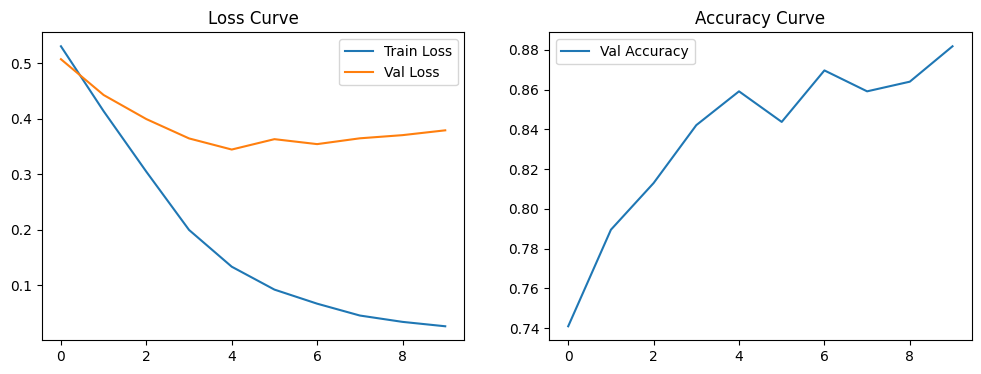

In [16]:
plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss Curve")

plt.subplot(1,2,2)
plt.plot(val_accuracies, label="Val Accuracy")
plt.legend()
plt.title("Accuracy Curve")

plt.show()

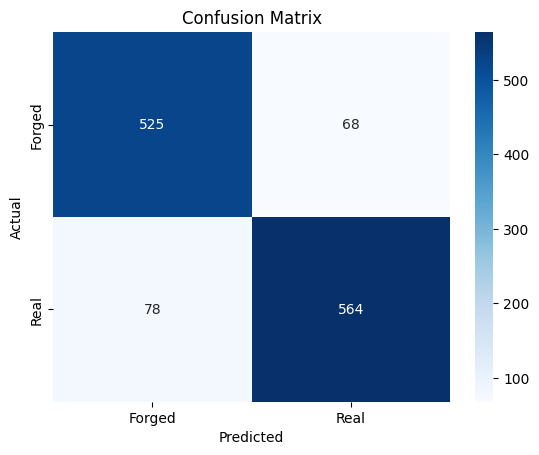

In [17]:
def plot_confusion_matrix(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = (outputs > 0.5).float().cpu().numpy()

            all_preds.extend(preds.squeeze())
            all_labels.extend(labels.numpy())

    cm = confusion_matrix(all_labels, all_preds)

    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Forged","Real"],
                yticklabels=["Forged","Real"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("Confusion Matrix")
    plt.show()

plot_confusion_matrix(model, val_loader)

In [18]:
def classification_metrics(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = (outputs > 0.5).float().cpu().numpy()

            all_preds.extend(preds.squeeze())
            all_labels.extend(labels.numpy())

    print(classification_report(all_labels, all_preds, target_names=["Forged","Real"]))

classification_metrics(model, val_loader)

              precision    recall  f1-score   support

      Forged       0.87      0.89      0.88       593
        Real       0.89      0.88      0.89       642

    accuracy                           0.88      1235
   macro avg       0.88      0.88      0.88      1235
weighted avg       0.88      0.88      0.88      1235



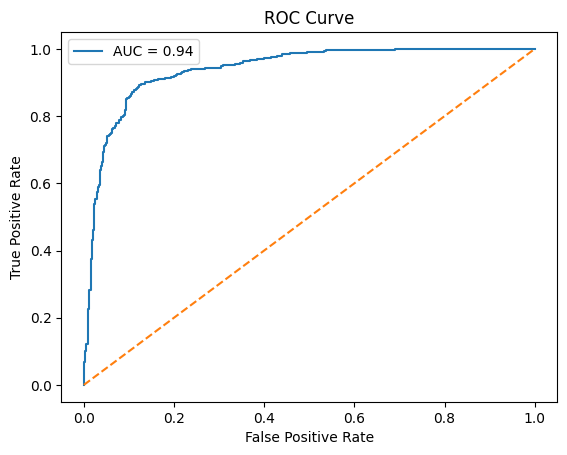

In [19]:
def plot_roc_curve(model, loader):
    model.eval()
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)

            all_probs.extend(outputs.cpu().numpy())
            all_labels.extend(labels.numpy())

    fpr, tpr, _ = roc_curve(all_labels, all_probs)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
    plt.plot([0,1],[0,1],'--')
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.title("ROC Curve")
    plt.show()

plot_roc_curve(model, val_loader)

In [20]:
torch.save(model.state_dict(), "resnet_signature_best.pth")

In [21]:
def predict_label(image_path):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image)

    if output.item() > 0.5:
        return "Real Signature"
    else:
        return "Forged Signature"

In [22]:
target_layer = model.layer4

activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_in, grad_out):
    global gradients
    gradients = grad_out[0]

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

In [23]:
def generate_gradcam(image_path):
    img = Image.open(image_path).convert("RGB")
    img_tensor = transform(img).unsqueeze(0).to(device)

    output = model(img_tensor)
    model.zero_grad()
    output.backward()

    grad = gradients.cpu().data.numpy()[0]
    act = activations.cpu().data.numpy()[0]

    weights = np.mean(grad, axis=(1,2))
    cam = np.zeros(act.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * act[i]

    cam = np.maximum(cam, 0)
    cam = cv2.resize(cam, (224,224))
    cam = cam / cam.max()

    return cam, img

In [24]:
def show_gradcam(image_path):

    prediction = predict_label(image_path)
    cam, img = generate_gradcam(image_path)

    img = img.resize((224,224))
    img = np.array(img)

    heatmap = cv2.applyColorMap(np.uint8(255*cam), cv2.COLORMAP_JET)
    superimposed = heatmap * 0.4 + img

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.title("Original")
    plt.imshow(img)
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.title("Heatmap")
    plt.imshow(heatmap)
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.title(f"Prediction: {prediction}")
    plt.imshow(superimposed.astype(np.uint8))
    plt.axis("off")

    plt.show()

In [25]:
!pip install lime
from lime import lime_image
from skimage.segmentation import mark_boundaries

In [26]:
def lime_predict(images):
    images = torch.tensor(images).permute(0,3,1,2).float() / 255.0
    images = images.to(device)
    outputs = model(images)
    probs = torch.cat([1-outputs, outputs], dim=1)
    return probs.detach().cpu().numpy()

In [27]:
def show_lime(image_path):
    img = Image.open(image_path).convert("RGB").resize((224,224))
    img_np = np.array(img)

    explainer = lime_image.LimeImageExplainer()
    explanation = explainer.explain_instance(
        img_np,
        lime_predict,
        top_labels=2,
        hide_color=0,
        num_samples=1500
    )

    temp, mask = explanation.get_image_and_mask(
        explanation.top_labels[0],
        positive_only=False,
        num_features=8,
        hide_rest=False
    )

    plt.imshow(mark_boundaries(temp/255.0, mask))
    plt.title("LIME Explanation")
    plt.axis("off")
    plt.show()

sys:1: UserWarning: Full backward hook is firing when gradients are computed with respect to module outputs since no inputs require gradients. See https://docs.pytorch.org/docs/main/generated/torch.nn.Module.html#torch.nn.Module.register_full_backward_hook for more details.


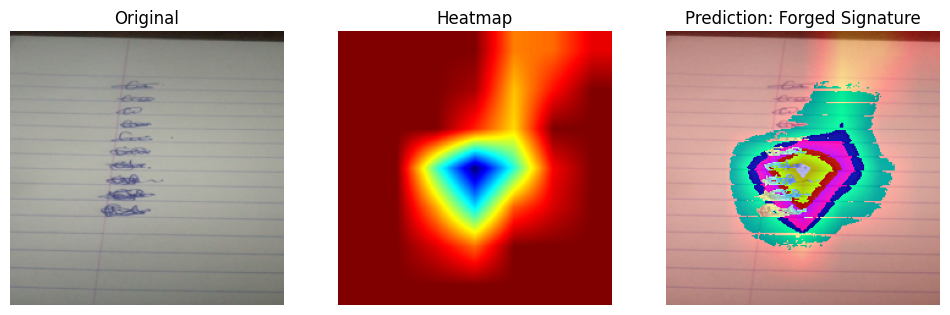

  0%|          | 0/1500 [00:00<?, ?it/s]

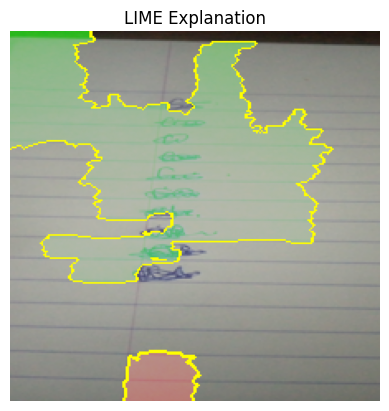

In [28]:
def get_random_image(base_path):
    image_paths = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.lower().endswith(('.png','.jpg','.jpeg')):
                image_paths.append(os.path.join(root,file))
    return random.choice(image_paths)

real_root = data_path + "/real"
test_img = get_random_image(real_root)

show_gradcam(test_img)
show_lime(test_img)